# Transformers from Scratch (NumPy only)
**Mathematical Foundations and Python Implementation — Questions 1–10**

Only `numpy` (compute), `matplotlib` (plots) and `time` (benchmark) are used.
No PyTorch / TensorFlow / Keras / JAX / prebuilt attention layers.

Shape notation: `n` = number of tokens, `d_model` = model width, `H` = heads, `d_k = d_v = d_model/H`.
Handwritten derivations live in the companion notes PDF; each section below verifies the hand-computed numbers in code.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)

## Question 1 — Sinusoidal Positional Encoding

$$PE(pos,2i)=\sin\!\Big(\frac{pos}{10000^{2i/d}}\Big),\qquad PE(pos,2i+1)=\cos\!\Big(\frac{pos}{10000^{2i/d}}\Big)$$

**(a) Roles.** `pos` = token index (0…n−1); `i` = index of the sin/cos *pair* (0…d/2−1); `d` = model dimension;
`10000` = base that sets the wavelength range. Angular frequency of pair *i*:
$$\omega_i = 10000^{-2i/d}\;\Rightarrow\;\text{wavelength }\lambda_i = 2\pi\cdot 10000^{2i/d}.$$
$i=0$: $\omega=1$ (wavelength $2\pi\approx6.28$ tokens, **highest frequency**); $i\to d/2$: $\omega\to 10^{-4}$ (wavelength $\approx 62{,}832$ tokens, **lowest frequency**).
Frequencies decay geometrically with the dimension index, like the digits of a counter: fast-changing low digits, slow-changing high digits.

**(d) Interpretation.** Each sin/cos pair is periodic in `pos`. For a fixed offset $k$:
$$\begin{pmatrix}\sin\omega(p+k)\\\cos\omega(p+k)\end{pmatrix}=\begin{pmatrix}\cos\omega k&\sin\omega k\\-\sin\omega k&\cos\omega k\end{pmatrix}\begin{pmatrix}\sin\omega p\\\cos\omega p\end{pmatrix}$$
so $PE(p+k)$ is a **linear function (rotation) of $PE(p)$** that depends only on $k$ — the model can learn relative offsets.
High-frequency pairs resolve neighbouring positions; low-frequency pairs give coarse, long-range position; together they give each position a unique code.

In [2]:
def sinusoidal_positional_encoding(seq_len, d_model):
    """Return array with shape (seq_len, d_model)."""
    assert d_model % 2 == 0, "d_model must be even"
    pos = np.arange(seq_len)[:, None]                 # (seq_len, 1)
    two_i = np.arange(0, d_model, 2)[None, :]         # (1, d_model/2)  values 2i
    angle = pos / np.power(10000.0, two_i / d_model)  # (seq_len, d_model/2)
    pe = np.zeros((seq_len, d_model))                 # (seq_len, d_model)
    pe[:, 0::2] = np.sin(angle)                       # even dims -> sin
    pe[:, 1::2] = np.cos(angle)                       # odd dims  -> cos
    return pe

# (b) verify handwritten d=4, pos = 0,1,2
pe4 = sinusoidal_positional_encoding(3, 4)
print("PE (3x4) for d=4:\n", pe4)
hand = np.array([[0, 1, 0, 1],
                 [np.sin(1), np.cos(1), np.sin(0.01), np.cos(0.01)],
                 [np.sin(2), np.cos(2), np.sin(0.02), np.cos(0.02)]])
print("matches handwritten formulas:", np.allclose(pe4, hand))
print("rounded (4 d.p.):\n", np.round(hand, 4))

PE (3x4) for d=4:
 [[ 0.      1.      0.      1.    ]
 [ 0.8415  0.5403  0.01    1.    ]
 [ 0.9093 -0.4161  0.02    0.9998]]
matches handwritten formulas: True
rounded (4 d.p.):
 [[ 0.      1.      0.      1.    ]
 [ 0.8415  0.5403  0.01    1.    ]
 [ 0.9093 -0.4161  0.02    0.9998]]


shape: (20, 16)


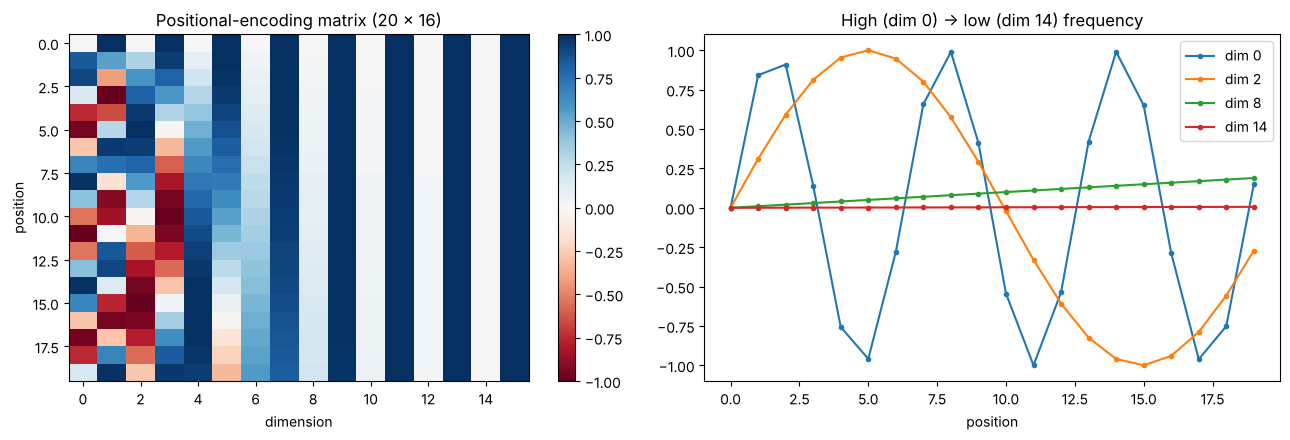

PE(p+k) is a fixed rotation of PE(p): True


In [3]:
# (c) seq_len = 20, d_model = 16
pe = sinusoidal_positional_encoding(20, 16)
print("shape:", pe.shape)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
im = ax[0].imshow(pe, cmap="RdBu", aspect="auto", vmin=-1, vmax=1)
ax[0].set_xlabel("dimension"); ax[0].set_ylabel("position"); ax[0].set_title("Positional-encoding matrix (20 x 16)")
plt.colorbar(im, ax=ax[0])
for d in [0, 2, 8, 14]:
    ax[1].plot(pe[:, d], marker="o", ms=3, label=f"dim {d}")
ax[1].set_xlabel("position"); ax[1].set_title("High (dim 0) -> low (dim 14) frequency"); ax[1].legend()
plt.tight_layout(); plt.show()

# (d) relative-position property: PE(p+k) = R(k) PE(p) for every sin/cos pair
d, k, p = 16, 3, 5
ok = True
for i in range(d // 2):
    w = 10000.0 ** (-2 * i / d)
    R = np.array([[np.cos(w*k), np.sin(w*k)], [-np.sin(w*k), np.cos(w*k)]])
    ok &= np.allclose(R @ pe[p, 2*i:2*i+2], sinusoidal_positional_encoding(p+k+1, d)[p+k, 2*i:2*i+2])
print("PE(p+k) is a fixed rotation of PE(p):", ok)

## Question 2 — Scaled Dot-Product Self-Attention

$$\text{Attention}(Q,K,V)=\text{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}}\Big)V$$

**(a)** Query = "what I look for", Key = "what I offer for matching", Value = "the content I pass on".
For $Q\in\mathbb R^{n\times d_k}$, $K\in\mathbb R^{n\times d_k}$: $QK^\top\in\mathbb R^{n\times n}$ (row *i* = scores of token *i* against all tokens); $V\in\mathbb R^{n\times d_v}\Rightarrow$ output $\in\mathbb R^{n\times d_v}$.
Scaling: if $q_j,k_j$ are independent with mean 0, variance 1, then $q\cdot k=\sum_{j=1}^{d_k}q_jk_j$ has variance $d_k$ (std $\sqrt{d_k}$). Dividing by $\sqrt{d_k}$ restores variance 1, so softmax is not pushed into saturation (near one-hot, vanishing gradients).

In [4]:
def softmax(x, axis=-1):
    """Manual softmax (max-subtracted for stability; proof in Q7)."""
    shifted = x - np.max(x, axis=axis, keepdims=True)
    e = np.exp(shifted)
    return e / np.sum(e, axis=axis, keepdims=True)

def scaled_dot_product_attention(Q, K, V):
    """Q:(n_queries,d_k), K:(n_keys,d_k), V:(n_keys,d_v)
    Return output (n_queries,d_v) and attention weights (n_queries,n_keys)."""
    d_k = Q.shape[-1]
    scores = Q @ K.T / np.sqrt(d_k)       # (n_queries, n_keys)
    weights = softmax(scores, axis=-1)    # rows sum to 1
    output = weights @ V                  # (n_queries, d_v)
    return output, weights

# (b) manual example
Q = K = V = np.array([[1., 0.], [0., 1.]])
print("QK^T:\n", Q @ K.T)
print("scaled scores (÷√2):\n", np.round(Q @ K.T / np.sqrt(2), 3))
out, w = scaled_dot_product_attention(Q, K, V)
print("attention weights:\n", np.round(w, 3))
print("output:\n", np.round(out, 3))

# (d) verification
hand_w = np.array([[0.670, 0.330], [0.330, 0.670]])   # handwritten (3 d.p.)
print("row sums:", w.sum(axis=1), "-> all 1:", np.allclose(w.sum(axis=1), 1))
print("python == handwritten weights:", np.allclose(w, hand_w, atol=1e-3))
print("python == handwritten output :", np.allclose(out, hand_w, atol=1e-3), "(V = I, so output = weights)")

QK^T:
 [[1. 0.]
 [0. 1.]]
scaled scores (÷√2):
 [[0.707 0.   ]
 [0.    0.707]]
attention weights:
 [[0.67 0.33]
 [0.33 0.67]]
output:
 [[0.67 0.33]
 [0.33 0.67]]
row sums: [1. 1.] -> all 1: True
python == handwritten weights: True
python == handwritten output : True (V = I, so output = weights)


## Question 3 — Learnable Q, K, V Projections

**(a)** $X\in\mathbb R^{n\times d_{model}}$, $W_Q,W_K\in\mathbb R^{d_{model}\times d_k}$, $W_V\in\mathbb R^{d_{model}\times d_v}$ ⇒ $Q,K\in\mathbb R^{n\times d_k}$, $V\in\mathbb R^{n\times d_v}$.
$W_Q,W_K$ must share $d_k$ (for $QK^\top$); $d_v$ is free (usually $d_k$; in MHA $d_{model}/H$).
The three differ because the roles differ: *matching-as-query*, *matching-as-key*, *content-to-send*. Separate matrices let the model learn asymmetric relations (A attends to B ≠ B attends to A) and decouple "what to look at" from "what to copy".

In [5]:
def self_attention(X, W_Q, W_K, W_V):
    """Compute Q, K, V projections and attention.
    X:(n,d_model) W_Q,W_K:(d_model,d_k) W_V:(d_model,d_v)
    Returns output (n,d_v), weights (n,n), and (Q,K,V)."""
    Q = X @ W_Q      # (n, d_k)
    K = X @ W_K      # (n, d_k)
    V = X @ W_V      # (n, d_v)
    out, weights = scaled_dot_product_attention(Q, K, V)
    return out, weights, (Q, K, V)

X   = np.array([[1., 2.], [0., 1.]])
W_Q = np.array([[1., 0.], [0., 1.]])
W_K = np.array([[0., 1.], [1., 0.]])
W_V = np.array([[2., 0.], [0., 1.]])

out, w, (Q, K, V) = self_attention(X, W_Q, W_K, W_V)
print("Q:\n", Q, "\nK:\n", K, "\nV:\n", V)
print("QK^T:\n", Q @ K.T)
print("scaled scores:\n", np.round(Q @ K.T / np.sqrt(2), 3))
print("weights:\n", np.round(w, 3))
print("output:\n", np.round(out, 3))

# (d) identity projections vs supplied projections
I = np.eye(2)
out_id, w_id, _ = self_attention(X, I, I, I)
print("\nIdentity projections -> weights:\n", np.round(w_id, 3), "\noutput:\n", np.round(out_id, 3))
print("Supplied projections -> weights:\n", np.round(w, 3))

Q:
 [[1. 2.]
 [0. 1.]] 
K:
 [[2. 1.]
 [1. 0.]] 
V:
 [[2. 2.]
 [0. 1.]]
QK^T:
 [[4. 1.]
 [1. 0.]]
scaled scores:
 [[2.828 0.707]
 [0.707 0.   ]]
weights:
 [[0.893 0.107]
 [0.67  0.33 ]]
output:
 [[1.786 1.893]
 [1.34  1.67 ]]

Identity projections -> weights:
 [[0.893 0.107]
 [0.67  0.33 ]] 
output:
 [[0.893 1.893]
 [0.67  1.67 ]]
Supplied projections -> weights:
 [[0.893 0.107]
 [0.67  0.33 ]]


**(d) Analysis.** With identity projections the scores are $XX^\top=\begin{pmatrix}5&2\\2&1\end{pmatrix}$ (raw dot-product similarity; always symmetric). With the supplied matrices the scores are $\begin{pmatrix}4&1\\1&0\end{pmatrix}$:
$W_K$ swaps the feature axes, so token 1's query $(1,2)$ is compared with swapped keys $(2,1)$ and token 2's query $(0,1)$ with its swapped key $(1,0)$ (score 0 with itself), so token 2 now attends *more to token 1 than to itself*.
$QK^\top$ is symmetric here only by coincidence; in general $QK^\top\neq(QK^\top)^\top$, so "A attends to B" ≠ "B attends to A". $W_V$ doubles feature 1 of the values, changing *what* is passed on.
Projections re-define similarity and content, so token relationships are learned rather than fixed by raw embeddings.

## Question 4 — Causal Self-Attention and Masking

Autoregressive generation predicts token $t+1$ from tokens $\le t$; at training time all positions are processed in parallel, so
position *i* must be **prevented from seeing positions $j>i$** (otherwise it could copy the answer). Adding $-\infty$ to those scores makes their softmax weight exactly 0.

4×4 causal mask $M$ ($0$ allowed, $-\infty$ blocked):
```
[[ 0, -inf, -inf, -inf],
 [ 0,   0,  -inf, -inf],
 [ 0,   0,    0,  -inf],
 [ 0,   0,    0,    0 ]]
```

In [6]:
def causal_mask(n_q, n_k=None):
    """M[i,j] = 0 if j <= i else -inf   (shape (n_q, n_k))"""
    n_k = n_q if n_k is None else n_k
    return np.triu(np.full((n_q, n_k), -np.inf), k=1)   # -inf strictly above diagonal, 0 elsewhere

def causal_self_attention(Q, K, V):
    """Return causally masked attention output and weights."""
    n, d_k = Q.shape
    scores = Q @ K.T / np.sqrt(d_k)        # (n, n)
    scores = scores + causal_mask(n)       # block future tokens
    weights = softmax(scores, axis=-1)     # exp(-inf) = 0
    return weights @ V, weights

print("4x4 mask:\n", causal_mask(4))

Q = K = V = np.array([[1., 0.], [0., 1.], [1., 1.]])
print("\nscaled scores:\n", np.round(Q @ K.T / np.sqrt(2), 3))
print("masked scores:\n", np.round(Q @ K.T / np.sqrt(2) + causal_mask(3), 3))
out, w = causal_self_attention(Q, K, V)
print("weights:\n", np.round(w, 3))
print("output:\n", np.round(out, 3))

# (d) verification
print("\nall future weights zero:", np.all(w[np.triu_indices(3, k=1)] == 0))
print("rows sum to 1:", np.allclose(w.sum(1), 1))
print("token-1 probs:", np.round(w[0], 3), " token-2 probs:", np.round(w[1], 3))

4x4 mask:
 [[  0. -inf -inf -inf]
 [  0.   0. -inf -inf]
 [  0.   0.   0. -inf]
 [  0.   0.   0.   0.]]

scaled scores:
 [[0.707 0.    0.707]
 [0.    0.707 0.707]
 [0.707 0.707 1.414]]
masked scores:
 [[0.707  -inf  -inf]
 [0.    0.707  -inf]
 [0.707 0.707 1.414]]
weights:
 [[1.    0.    0.   ]
 [0.33  0.67  0.   ]
 [0.248 0.248 0.503]]
output:
 [[1.    0.   ]
 [0.33  0.67 ]
 [0.752 0.752]]

all future weights zero: True
rows sum to 1: True
token-1 probs: [1. 0. 0.]  token-2 probs: [0.33 0.67 0.  ]


**Causal vs padding mask.** A *causal* mask is triangular and depends only on positions (hides the future from each query).
A *padding* mask depends on the data: it hides `<pad>` **key columns** (same for every query row) so real tokens never attend to padding. They are often combined (add both masks).

In [7]:
# padding mask demo: sequence of 3 real tokens + 1 pad  -> block column 3 for every row
pad = np.array([0, 0, 0, 1])                      # 1 = padding token
pad_mask = np.where(pad[None, :] == 1, -np.inf, 0.0) * np.ones((4, 1))
print(pad_mask)

[[  0.   0.   0. -inf]
 [  0.   0.   0. -inf]
 [  0.   0.   0. -inf]
 [  0.   0.   0. -inf]]


## Question 5 — Cross-Attention (Encoder–Decoder)

**(a)** Self-attention: Q, K, V all come from the *same* sequence. Cross-attention: $Q=H_{dec}W_Q$ (decoder, $n$ tokens) while $K=H_{enc}W_K,\;V=H_{enc}W_V$ (encoder, $m$ tokens).
Scores $QK^\top\in\mathbb R^{n\times m}$; weights $\in\mathbb R^{n\times m}$; output $\in\mathbb R^{n\times d_v}$ (one vector per decoder token).

In [8]:
def cross_attention(decoder_states, encoder_states, W_Q, W_K, W_V):
    """decoder_states:(n,d_model) encoder_states:(m,d_model)
    Returns outputs (n,d_v) and weights (n,m)."""
    Q = decoder_states @ W_Q      # (n, d_k)
    K = encoder_states @ W_K      # (m, d_k)
    V = encoder_states @ W_V      # (m, d_v)
    return scaled_dot_product_attention(Q, K, V)

# (b) manual example (use the core attention directly: K and V are given separately)
Q = np.array([[1., 0.]])
K = np.array([[1., 0.], [0., 1.], [1., 1.]])
V = np.array([[2., 0.], [0., 2.], [1., 1.]])
print("scaled scores:", np.round(Q @ K.T / np.sqrt(2), 3))
out, w = scaled_dot_product_attention(Q, K, V)
print("weights:", np.round(w, 3), "(sum =", w.sum().round(3), ")")
print("output :", np.round(out, 3))

# (c) generic usage with n=3 decoder tokens, m=5 encoder tokens, d_model=8
dec, enc = rng.normal(size=(3, 8)), rng.normal(size=(5, 8))
Wq, Wk, Wv = (rng.normal(scale=0.3, size=(8, 8)) for _ in range(3))
o, a = cross_attention(dec, enc, Wq, Wk, Wv)
print("\noutput shape:", o.shape, " weights shape:", a.shape, " (n x m, NOT square)")
print("rows sum to 1:", np.allclose(a.sum(1), 1))

scaled scores: [[0.707 0.    0.707]]
weights: [[0.401 0.198 0.401]] (sum = 1.0 )
output : [[1.203 0.797]]

output shape: (3, 8)  weights shape: (3, 5)  (n x m, NOT square)
rows sum to 1: True


**(d) Interpretation.** Each decoder token forms a query that "asks" the source sentence a question; the softmax over the $m$ encoder positions says *which source tokens to read*, and the output is the weighted mix of their values — source-information retrieval (e.g. an English word attending to the French word it translates).
The matrix is $n\times m$ because rows index target positions and columns index source positions; source and target lengths are independent, so it is generally non-square.

## Question 6 — Multi-Head Attention

**(a)** $d_{model}=8,\;H=2,\;d_k=d_v=4$. Per head: $W_Q^{(h)},W_K^{(h)},W_V^{(h)}\in\mathbb R^{8\times4}$; $Q_h,K_h,V_h\in\mathbb R^{n\times4}$; scores/weights $\in\mathbb R^{n\times n}$; head output $\in\mathbb R^{n\times4}$.
Concat of 2 heads: $n\times8$; $W_O\in\mathbb R^{8\times8}$; final output $n\times8$.
(Implementation uses one fused $8\times8$ matrix per Q/K/V whose column blocks are the per-head matrices.)

In [9]:
def multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads, causal=False, X_kv=None):
    """X:(n_q,d_model)  W_Q,W_K,W_V,W_O:(d_model,d_model)
    X_kv: optional key/value source (cross-attention). causal: apply causal mask.
    Returns output (n_q,d_model) and weights (num_heads,n_q,n_k)."""
    X_kv = X if X_kv is None else X_kv
    n_q, d_model = X.shape
    n_k = X_kv.shape[0]
    H = num_heads
    d_k = d_model // H
    Q, K, V = X @ W_Q, X_kv @ W_K, X_kv @ W_V                  # (n, d_model)
    # split into heads: (n, H*d_k) -> (H, n, d_k)
    Qh = Q.reshape(n_q, H, d_k).transpose(1, 0, 2)
    Kh = K.reshape(n_k, H, d_k).transpose(1, 0, 2)
    Vh = V.reshape(n_k, H, d_k).transpose(1, 0, 2)
    scores = Qh @ Kh.transpose(0, 2, 1) / np.sqrt(d_k)          # (H, n_q, n_k)
    if causal:
        scores = scores + causal_mask(n_q, n_k)[None]           # broadcast over heads
    weights = softmax(scores, axis=-1)                          # (H, n_q, n_k)
    heads = weights @ Vh                                        # (H, n_q, d_k)
    concat = heads.transpose(1, 0, 2).reshape(n_q, H * d_k)     # (n_q, d_model)
    return concat @ W_O, weights                                # (n_q, d_model)

# (b) handwritten example, one explicit matrix per head
X = np.array([[1., 0.], [0., 1.]])
I2 = np.eye(2); P = np.array([[0., 1.], [1., 0.]])
head1, w1 = scaled_dot_product_attention(X @ I2, X @ I2, X @ I2)
head2, w2 = scaled_dot_product_attention(X @ P,  X @ P,  X @ I2)
print("head 1 weights:\n", np.round(w1, 3), "\nhead 1 output:\n", np.round(head1, 3))
print("head 2 Q=K:\n", X @ P)
print("head 2 weights:\n", np.round(w2, 3), "\nhead 2 output:\n", np.round(head2, 3))
print("concat (2x4):\n", np.round(np.concatenate([head1, head2], axis=1), 3))

# (c) test with d_model=8, H=2
n, d_model, H = 4, 8, 2
X = rng.normal(size=(n, d_model))
Wq, Wk, Wv, Wo = (rng.normal(scale=0.3, size=(d_model, d_model)) for _ in range(4))
out, w = multi_head_attention(X, Wq, Wk, Wv, Wo, H)
print("\noutput", out.shape, "weights", w.shape, "| rows sum to 1:", np.allclose(w.sum(-1), 1))

# independent check of head 0 using column slices
d_k = d_model // H
h0, w0 = scaled_dot_product_attention(X @ Wq[:, :d_k], X @ Wk[:, :d_k], X @ Wv[:, :d_k])
print("head-0 weights match independent computation:", np.allclose(w[0], w0))
# H=1 reduces to single-head attention + W_O
o1, _ = multi_head_attention(X, Wq, Wk, Wv, Wo, 1)
o_ref, _ = scaled_dot_product_attention(X @ Wq, X @ Wk, X @ Wv)
print("H=1 equals single-head attention @ W_O:", np.allclose(o1, o_ref @ Wo))

head 1 weights:
 [[0.67 0.33]
 [0.33 0.67]] 
head 1 output:
 [[0.67 0.33]
 [0.33 0.67]]
head 2 Q=K:
 [[0. 1.]
 [1. 0.]]
head 2 weights:
 [[0.67 0.33]
 [0.33 0.67]] 
head 2 output:
 [[0.67 0.33]
 [0.33 0.67]]
concat (2x4):
 [[0.67 0.33 0.67 0.33]
 [0.33 0.67 0.33 0.67]]

output (4, 8) weights (2, 4, 4) | rows sum to 1: True
head-0 weights match independent computation: True
H=1 equals single-head attention @ W_O: True


**(d) Analysis.** Each head has its own projections, so each looks at a different subspace of the features and can specialise (e.g. local syntax, long-range coreference, positional patterns); the concatenation + $W_O$ mixes these views.
More heads do **not** automatically add capacity: with $d_k=d_{model}/H$ the *total* parameter count ($4d_{model}^2$) is unchanged; adding heads makes each head narrower (lower-rank scores, $d_k$ smaller), many heads end up redundant or prunable, and compute/memory for attention weights grows as $H\,n^2$.

## Question 7 — Numerical Stability and Temperature

**(a) Proof.** Let $c=\max_j z_j$:
$$\text{softmax}(z-c)_i=\frac{e^{z_i-c}}{\sum_j e^{z_j-c}}=\frac{e^{-c}e^{z_i}}{e^{-c}\sum_j e^{z_j}}=\frac{e^{z_i}}{\sum_j e^{z_j}}=\text{softmax}(z)_i\;\blacksquare$$
After subtraction the largest exponent is $e^0=1$, so no overflow; the denominator is $\ge1$, so no division by zero.

In [10]:
def stable_softmax(x, axis=-1):
    """Numerically stable NumPy softmax."""
    x = np.asarray(x, dtype=float)
    e = np.exp(x - np.max(x, axis=axis, keepdims=True))
    return e / np.sum(e, axis=axis, keepdims=True)

z = np.array([1000., 1001., 1002.])
with np.errstate(over="ignore", invalid="ignore"):
    direct = np.exp(z) / np.sum(np.exp(z))
print("direct exponentiation:", direct, "  <- inf/inf = nan")
print("stable softmax       :", stable_softmax(z))
print("equals softmax([0,1,2]):", np.allclose(stable_softmax(z), stable_softmax(np.array([0., 1., 2.]))))

direct exponentiation: [nan nan nan]   <- inf/inf = nan
stable softmax       : [0.09   0.2447 0.6652]
equals softmax([0,1,2]): True


T=0.5  row-0 probs=[0.001 0.    0.952 0.047 0.   ]  max=0.952  mean entropy=0.574
T=1    row-0 probs=[0.023 0.01  0.78  0.173 0.014]  max=0.780  mean entropy=1.080
T=2    row-0 probs=[0.092 0.059 0.529 0.25  0.071]  max=0.529  mean entropy=1.428
T=4    row-0 probs=[0.148 0.119 0.357 0.245 0.131]  max=0.357  mean entropy=1.560


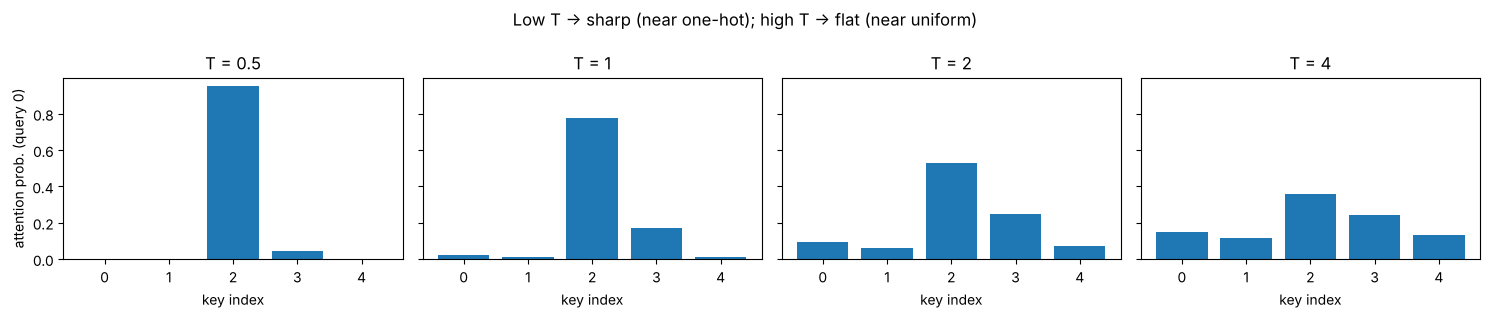


d_k=4     std(q.k)=   2.01  (sqrt(d_k)=  2.00)  std after scaling=1.01
d_k=64    std(q.k)=   7.90  (sqrt(d_k)=  8.00)  std after scaling=0.99
d_k=256   std(q.k)=  15.98  (sqrt(d_k)= 16.00)  std after scaling=1.00
d_k=1024  std(q.k)=  32.24  (sqrt(d_k)= 32.00)  std after scaling=1.01
logit scale x1   max p=0.186  ||Jacobian||_F=0.3497
logit scale x5   max p=0.334  ||Jacobian||_F=0.4080
logit scale x20  max p=0.692  ||Jacobian||_F=0.3449
logit scale x100 max p=0.999  ||Jacobian||_F=0.0014


In [11]:
# (c) temperature experiment: softmax(QK^T / T)
rng7 = np.random.default_rng(1)
Q = rng7.normal(size=(5, 4)); K = rng7.normal(size=(5, 4))
scores = Q @ K.T
temps = [0.5, 1, 2, 4]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, T in zip(axes, temps):
    p = stable_softmax(scores / T, axis=-1)
    ax.bar(range(5), p[0]); ax.set_title(f"T = {T}"); ax.set_xlabel("key index")
    entropy = -(p * np.log(p)).sum(-1).mean()
    print(f"T={T:<4} row-0 probs={np.round(p[0],3)}  max={p[0].max():.3f}  mean entropy={entropy:.3f}")
axes[0].set_ylabel("attention prob. (query 0)")
plt.suptitle("Low T -> sharp (near one-hot); high T -> flat (near uniform)"); plt.tight_layout(); plt.show()

# sqrt(d_k) scaling and gradient demo
print()
for d_k in [4, 64, 256, 1024]:
    q = rng7.normal(size=(2000, d_k)); k = rng7.normal(size=(2000, d_k))
    dots = (q * k).sum(1)
    print(f"d_k={d_k:<5} std(q.k)={dots.std():7.2f}  (sqrt(d_k)={np.sqrt(d_k):6.2f})  std after scaling={ (dots/np.sqrt(d_k)).std():.2f}")

def softmax_jacobian(p):          # dp_i/dz_j = p_i(delta_ij - p_j)
    return np.diag(p) - np.outer(p, p)
z = rng7.normal(size=8)
for scale in [1, 5, 20, 100]:
    p = stable_softmax(scale * z)
    print(f"logit scale x{scale:<3} max p={p.max():.3f}  ||Jacobian||_F={np.linalg.norm(softmax_jacobian(p)):.4f}")

**(d) Explanation.** Dividing scores by temperature $T$ sharpens ($T<1$) or flattens ($T>1$) the distribution. Large $d_k$ makes dot products have std $\sqrt{d_k}$, i.e. acts like a very low temperature: softmax is nearly one-hot.
The Jacobian $\partial p_i/\partial z_j=p_i(\delta_{ij}-p_j)$ then goes to 0 (as shown above) → **vanishing gradients**. Scaling by $1/\sqrt{d_k}$ keeps the logits at $O(1)$ so gradients stay useful.

## Question 8 — Transformer Encoder Block (post-norm)

$$H=\text{LayerNorm}(X+\text{MHA}(X)),\qquad Y=\text{LayerNorm}(H+\text{FFN}(H)),\qquad \text{FFN}(H)=\max(0,HW_1+b_1)W_2+b_2$$
Dimensions: $X:(n,d_{model})$ → MHA $(n,d_{model})$ → add&norm $(n,d_{model})$ → FFN $(n,d_{model})\to(n,d_{ff})\to(n,d_{model})$ → add&norm → $Y:(n,d_{model})$.

In [12]:
def layer_norm(X, gamma, beta, eps=1e-5):
    """Normalise each token across features. X:(n,d) gamma,beta:(d,)"""
    mean = X.mean(axis=-1, keepdims=True)            # (n,1)
    var = X.var(axis=-1, keepdims=True)              # (n,1)  (biased, 1/d)
    return gamma * (X - mean) / np.sqrt(var + eps) + beta

def feed_forward(X, W1, b1, W2, b2):
    """Position-wise FFN. X:(n,d_model) W1:(d_model,d_ff) W2:(d_ff,d_model)"""
    return np.maximum(0, X @ W1 + b1) @ W2 + b2

def init_encoder_params(d_model, d_ff, rng):
    g = lambda *s: rng.normal(scale=0.3, size=s)
    return dict(W_Q=g(d_model, d_model), W_K=g(d_model, d_model), W_V=g(d_model, d_model), W_O=g(d_model, d_model),
                W1=g(d_model, d_ff), b1=np.zeros(d_ff), W2=g(d_ff, d_model), b2=np.zeros(d_model),
                gamma1=np.ones(d_model), beta1=np.zeros(d_model),
                gamma2=np.ones(d_model), beta2=np.zeros(d_model), num_heads=2)

def transformer_encoder_block(X, params):
    """Return (seq_len,d_model) output."""
    p = params
    attn, _ = multi_head_attention(X, p["W_Q"], p["W_K"], p["W_V"], p["W_O"], p["num_heads"])
    H = layer_norm(X + attn, p["gamma1"], p["beta1"])                       # (n,d_model)
    ffn = feed_forward(H, p["W1"], p["b1"], p["W2"], p["b2"])               # (n,d_model)
    return layer_norm(H + ffn, p["gamma2"], p["beta2"])                     # (n,d_model)

n, d_model, d_ff = 6, 8, 16
X = rng.normal(size=(n, d_model))
params = init_encoder_params(d_model, d_ff, rng)
Y = transformer_encoder_block(X, params)
print("input", X.shape, "-> output", Y.shape)
print("per-token mean ~0:", np.allclose(Y.mean(-1), 0, atol=1e-6), "| per-token var ~1:", np.allclose(Y.var(-1), 1, atol=1e-3))

# attention mixes tokens (permutation-EQUIVARIANT without positional encoding), FFN acts per token
perm = rng.permutation(n)
print("block(X[perm]) == block(X)[perm]:", np.allclose(transformer_encoder_block(X[perm], params), Y[perm]))
f = feed_forward(X, params["W1"], params["b1"], params["W2"], params["b2"])
print("FFN row i depends only on row i:", np.allclose(feed_forward(X[[2]], params["W1"], params["b1"], params["W2"], params["b2"]), f[[2]]))
X2 = X.copy(); X2[0] += 1.0       # change token 0 only
a1, _ = multi_head_attention(X, params["W_Q"], params["W_K"], params["W_V"], params["W_O"], 2)
a2, _ = multi_head_attention(X2, params["W_Q"], params["W_K"], params["W_V"], params["W_O"], 2)
print("changing token 0 changes MHA output of other tokens:", not np.allclose(a1[1:], a2[1:]))

input (6, 8) -> output (6, 8)
per-token mean ~0: True | per-token var ~1: True
block(X[perm]) == block(X)[perm]: True
FFN row i depends only on row i: True
changing token 0 changes MHA output of other tokens: True


**Architecture sketch (post-norm encoder block)**
```
 X (n, d_model) ───────────────┐
   │                           │
 Multi-Head Self-Attention     │ residual
   │ (n, d_model)              │
   └──────────── (+) ◄─────────┘
        LayerNorm  → H (n, d_model) ──────┐
          │                               │
   FFN: Linear(d_model→d_ff) → ReLU → Linear(d_ff→d_model)   │ residual
          └─────────── (+) ◄──────────────┘
                 LayerNorm → Y (n, d_model)
```
**(c)** FFN uses the same weights on each row separately → no information moves between tokens; attention is the *only* sublayer that mixes tokens (weighted sums over rows of V).
Residual connections give $\partial(x+F(x))/\partial x=I+\partial F/\partial x$: the identity term lets gradients flow unattenuated through many layers (avoids vanishing gradients) and makes each layer learn a *correction*.

## Question 9 — Decoder Block and Complete Architecture

Decoder block (post-norm): (1) masked self-attention → (2) Add&Norm → (3) cross-attention (Q from decoder, K/V from encoder output) → (4) Add&Norm → (5) FFN → (6) Add&Norm.

Full model: `source tokens → embedding(+scale) + PE → N× encoder blocks → memory (m, d)`;
`shifted target tokens → embedding + PE → N× decoder blocks (each reads memory) → Linear(d_model→vocab) → softmax`.

In [13]:
def init_decoder_params(d_model, d_ff, rng, num_heads=2):
    g = lambda *s: rng.normal(scale=0.3, size=s)
    attn = lambda: dict(W_Q=g(d_model, d_model), W_K=g(d_model, d_model), W_V=g(d_model, d_model), W_O=g(d_model, d_model))
    ones, zeros = np.ones(d_model), np.zeros(d_model)
    return dict(self_attn=attn(), cross_attn=attn(), num_heads=num_heads,
                W1=g(d_model, d_ff), b1=np.zeros(d_ff), W2=g(d_ff, d_model), b2=zeros.copy(),
                gamma1=ones, beta1=zeros, gamma2=ones, beta2=zeros, gamma3=ones, beta3=zeros)

def transformer_decoder_block(decoder_input, encoder_output, params):
    """decoder_input:(n,d_model) encoder_output:(m,d_model) -> (n,d_model)"""
    p, H = params, params["num_heads"]
    sa, ca = p["self_attn"], p["cross_attn"]
    # (1) masked self-attention, (2) add & norm
    a1, _ = multi_head_attention(decoder_input, sa["W_Q"], sa["W_K"], sa["W_V"], sa["W_O"], H, causal=True)
    x1 = layer_norm(decoder_input + a1, p["gamma1"], p["beta1"])                       # (n,d)
    # (3) cross-attention: Q from decoder, K,V from encoder; (4) add & norm
    a2, w_cross = multi_head_attention(x1, ca["W_Q"], ca["W_K"], ca["W_V"], ca["W_O"], H, X_kv=encoder_output)
    x2 = layer_norm(x1 + a2, p["gamma2"], p["beta2"])                                  # (n,d)
    # (5) FFN, (6) add & norm
    f = feed_forward(x2, p["W1"], p["b1"], p["W2"], p["b2"])
    out = layer_norm(x2 + f, p["gamma3"], p["beta3"])                                  # (n,d)
    transformer_decoder_block.last_cross_weights = w_cross                             # kept for inspection
    return out

d_model, H, m, n, d_ff = 8, 2, 5, 3, 16
enc_out = rng.normal(size=(m, d_model))        # encoder length 5
dec_in  = rng.normal(size=(n, d_model))        # decoder length 3
dp = init_decoder_params(d_model, d_ff, rng, H)
out = transformer_decoder_block(dec_in, enc_out, dp)

sa, ca = dp["self_attn"], dp["cross_attn"]
_, w_self = multi_head_attention(dec_in, sa["W_Q"], sa["W_K"], sa["W_V"], sa["W_O"], H, causal=True)
w_cross = transformer_decoder_block.last_cross_weights
print("decoder input        :", dec_in.shape)
print("encoder output       :", enc_out.shape)
print("masked self-attn wts :", w_self.shape, " (H, n, n)")
print("cross-attn weights   :", w_cross.shape, " (H, n, m)  <- non-square")
print("decoder output       :", out.shape, " (n, d_model)")
assert out.shape == (n, d_model) and w_self.shape == (H, n, n) and w_cross.shape == (H, n, m)
print("future self-attn weights are zero:", np.all(np.triu(w_self, k=1) == 0))
print("cross-attn rows sum to 1:", np.allclose(w_cross.sum(-1), 1))

# causality test: changing a later decoder token must not change earlier outputs
dec2 = dec_in.copy(); dec2[2] += 5.0
out2 = transformer_decoder_block(dec2, enc_out, dp)
print("outputs for tokens 0,1 unchanged when token 2 changes:", np.allclose(out[:2], out2[:2]))
# ...but changing the encoder output changes every decoder position
out3 = transformer_decoder_block(dec_in, enc_out + 1.0 * rng.normal(size=enc_out.shape), dp)
print("all decoder outputs depend on encoder output:", not np.any(np.isclose(out, out3).all(axis=1)))

decoder input        : (3, 8)
encoder output       : (5, 8)
masked self-attn wts : (2, 3, 3)  (H, n, n)
cross-attn weights   : (2, 3, 5)  (H, n, m)  <- non-square
decoder output       : (3, 8)  (n, d_model)
future self-attn weights are zero: True
cross-attn rows sum to 1: True
outputs for tokens 0,1 unchanged when token 2 changes: True
all decoder outputs depend on encoder output: True


**(c) Information flow & masking.** Source tokens → embeddings + PE → encoder self-attention (every source token sees every other) → encoder output `memory` $(m,d)$. In each decoder block the cross-attention keys/values are `memory`, so every decoder position can read *any* source token; the result is mixed through FFN/Add&Norm and finally projected to vocabulary logits.
The decoder needs the causal mask because at inference it generates left-to-right and future target tokens do not exist; training in parallel with teacher forcing would otherwise leak the answer. The encoder processes a fully known source sentence, so bidirectional context is allowed (and useful) — it only uses padding masks.

## Question 10 — Computational Complexity

Multiply-add counted as one operation. $n$ tokens, $d=d_{model}$, $H$ heads, $d_k=d/H$.

| Step | Per head | Total (all heads) |
|---|---|---|
| Q,K,V projections | $3\,n\,d\,d_k$ | $3nd^2$ |
| $QK^\top$ | $n^2d_k$ | $n^2 d$ |
| softmax | $n^2$ | $Hn^2$ |
| $AV$ | $n^2d_k$ | $n^2 d$ |
| Output projection | – | $nd^2$ |
| **Total** | | $O(nd^2+n^2d)$ |
| Attention-matrix memory | $n^2$ | $H\,n^2$ floats ($8Hn^2$ bytes in float64) |

n=  32 | time=   0.132 ms | attn-matrix mem=     32.0 KiB | theory MACs=655,360


n=  64 | time=   0.280 ms | attn-matrix mem=    128.0 KiB | theory MACs=1,572,864
n= 128 | time=   0.836 ms | attn-matrix mem=    512.0 KiB | theory MACs=4,194,304
n= 256 | time=   3.254 ms | attn-matrix mem=   2048.0 KiB | theory MACs=12,582,912


n= 512 | time=  22.238 ms | attn-matrix mem=   8192.0 KiB | theory MACs=41,943,040
n=  32 | time=   0.181 ms | attn-matrix mem=     32.0 KiB | theory MACs=655,360
n=  64 | time=   0.384 ms | attn-matrix mem=    128.0 KiB | theory MACs=1,572,864


n= 128 | time=   1.203 ms | attn-matrix mem=    512.0 KiB | theory MACs=4,194,304


n= 256 | time=   3.970 ms | attn-matrix mem=   2048.0 KiB | theory MACs=12,582,912


n= 512 | time=  28.850 ms | attn-matrix mem=   8192.0 KiB | theory MACs=41,943,040


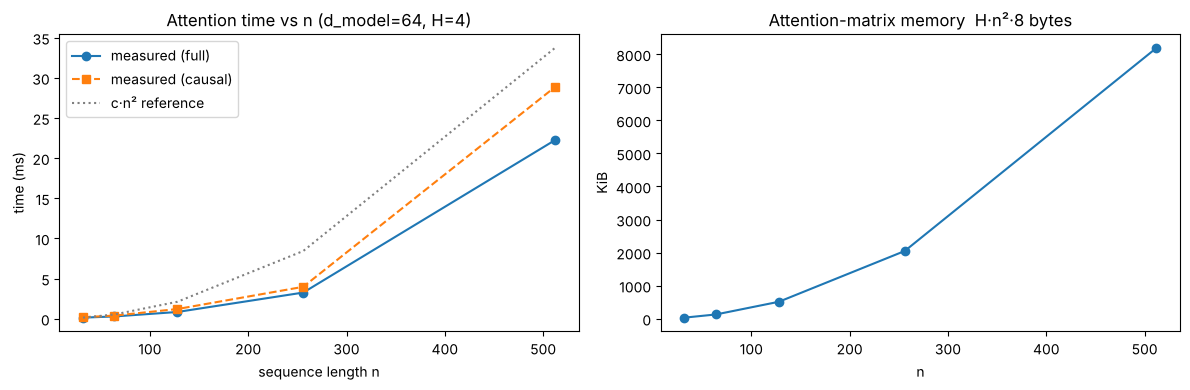

log-log slope of time vs n for n>=128: 2.37  (2 = pure quadratic; small n is dominated by overhead and the O(n d^2) projection terms, large n also shows cache/memory effects)
memory ratio n=512 vs n=256: 4.0 (expected 4)


In [14]:
def benchmark_attention(seq_lengths, d_model, num_heads, repeats=5, causal=False):
    """Report timing and attention-matrix memory."""
    bench = np.random.default_rng(42)
    Wq, Wk, Wv, Wo = (bench.normal(scale=0.1, size=(d_model, d_model)) for _ in range(4))
    rows = []
    for n in seq_lengths:
        X = bench.normal(size=(n, d_model))
        multi_head_attention(X, Wq, Wk, Wv, Wo, num_heads, causal=causal)        # warm-up
        times = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            multi_head_attention(X, Wq, Wk, Wv, Wo, num_heads, causal=causal)
            times.append(time.perf_counter() - t0)
        mem_bytes = num_heads * n * n * 8                                         # float64 attention weights
        flops = 3*n*d_model**2 + 2*n*n*d_model + n*d_model**2                     # theoretical mult-adds
        rows.append((n, np.median(times) * 1e3, mem_bytes / 1024, flops))
        print(f"n={n:4d} | time={rows[-1][1]:8.3f} ms | attn-matrix mem={rows[-1][2]:9.1f} KiB | theory MACs={flops:,}")
    return rows

lengths = [32, 64, 128, 256, 512]
res = benchmark_attention(lengths, d_model=64, num_heads=4)
res_causal = benchmark_attention(lengths, d_model=64, num_heads=4, causal=True)

n_arr = np.array([r[0] for r in res]); t_arr = np.array([r[1] for r in res])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(n_arr, t_arr, "o-", label="measured (full)")
ax[0].plot(n_arr, [r[1] for r in res_causal], "s--", label="measured (causal)")
ref = t_arr[0] * (n_arr / n_arr[0]) ** 2
ax[0].plot(n_arr, ref, ":", color="gray", label="c·n² reference")
ax[0].set_xlabel("sequence length n"); ax[0].set_ylabel("time (ms)"); ax[0].set_title("Attention time vs n (d_model=64, H=4)"); ax[0].legend()
ax[1].plot(n_arr, [r[2] for r in res], "o-"); ax[1].set_xlabel("n"); ax[1].set_ylabel("KiB"); ax[1].set_title("Attention-matrix memory  H·n²·8 bytes")
plt.tight_layout(); plt.show()
slope = np.polyfit(np.log(n_arr[2:]), np.log(t_arr[2:]), 1)[0]
print(f"log-log slope of time vs n for n>=128: {slope:.2f}  (2 = pure quadratic; small n is dominated by overhead and the O(n d^2) projection terms, large n also shows cache/memory effects)")
print("memory ratio n=512 vs n=256:", res[4][2] / res[3][2], "(expected 4)")

**(c) Analysis.** $QK^\top$ and $AV$ each cost $n^2d_k$ per head because every one of $n$ queries is compared with every one of $n$ keys → time and attention-matrix memory grow **quadratically** with $n$; doubling $n$ gives ≈4× memory.
*Head count:* total FLOPs for $QK^\top$/$AV$ are unchanged for fixed $d_{model}$ ($H\cdot n^2\cdot d/H$), but attention-matrix memory (and softmax work) grows ∝ $H$.
*Masking:* causal masking does **not** reduce arithmetic in the dense implementation above (the full $n\times n$ product is still computed, then masked; see equal timings). A specialised implementation (block-sparse / FlashAttention-style tiling) skips the upper-triangular blocks — an implementation-level saving of ≈½ the work, not a change of the formal $O(n^2)$ cost.
*Arithmetic cost vs implementation savings:* FLOPs count mathematical operations; actual speed also depends on memory bandwidth, vectorisation (BLAS), fused kernels, cache blocking, and not materialising the $n\times n$ matrix.
For short sequences ($n<d$) the $O(nd^2)$ projections dominate; for long sequences ($n>d$) the $O(n^2d)$ attention term dominates.